# NumPy Hands-on Lab: From Arrays to Image Analysis

## Student Practice Notebook

**Name:** MANOHAR KATLAGUNTA
**Register Number:** AP24110012036
**Date:** 10-08-2026  

## Learning Objectives

After completing this lab, you will be able to:

- Create and manipulate NumPy arrays
- Understand array properties and dimensions
- Perform indexing and slicing
- Apply mathematical operations
- Understand and explain broadcasting
- Analyze images using NumPy arrays
- Perform basic image transformations
- Explain *why* NumPy is used in real ML/Data Science pipelines, not just *how*

### How to use this notebook
- **Demonstration** cells: run them, read the output, understand it.
- **Practice** cells: write your own code — don't copy the demo verbatim.
- **Predict-then-run**: before running some cells, you'll be asked to *predict* the output first. Write your prediction in the markdown cell, then run and compare.
- **Reflection**: short written answers, in your own words.


## Part 1: Introduction to NumPy

NumPy (Numerical Python) is a Python library used for efficient numerical computation.

**Why not just use Python lists?** Python lists store objects with overhead per element and loop in pure Python. NumPy arrays store raw numbers in contiguous memory and use compiled C code for operations — this is called **vectorization**. That's why NumPy is used everywhere in:

- Data Science (pandas is built on NumPy)
- Machine Learning (feeding data into models as arrays/tensors)
- Image Processing (an image *is* a NumPy array)
- Scientific Computing

Let's actually *see* the speed difference before we take it on faith.


In [ ]:
import numpy as np # Import NumPy library for numerical operations
import matplotlib.pyplot as plt # Import Matplotlib's pyplot module for creating graphs and plots

print("NumPy is ready!") # Display


NumPy is ready!


### Demonstration: Loops vs. Vectorization (the "why" behind NumPy)

Below we add 1 to a million numbers two ways: a plain Python loop, and a NumPy array operation.
Run this cell and look at the timing output.


In [ ]:
import time # Import time to measure execution duration

n = 1_000_000 # Set the number of values to one million
python_list = list(range(n)) # Create a Python list containing numbers from 0 to n-1
numpy_array = np.arange(n) # Create a NumPy array containing numbers from 0 to n-1

start = time.time()  # Record the start time for the Python loop
result_list = [x + 1 for x in python_list]   # Add 1 to every list element using a Python loop
loop_time = time.time() - start    # Calculate the time taken by the Python loop

start = time.time()  # Record the start time for the NumPy operation
result_array = numpy_array + 1  # Add 1 to every array element using vectorization
vector_time = time.time() - start  # Calculate the time taken by the NumPy operation

print(f"Python loop time : {loop_time:.5f} seconds")  # Display Python loop execution time
print(f"NumPy vector time: {vector_time:.5f} seconds")  # Display NumPy execution time
print(f"NumPy was about {loop_time/vector_time:.0f}x faster")  # Display the approximate speedup



Python loop time : 0.11600 seconds
NumPy vector time: 0.00100 seconds
NumPy was about 116x faster


**Reflection (write your answer):** Based on the timing above, in your own words, why is NumPy faster than a Python loop for this kind of operation?

*Your answer:* NumPy is faster because it can do the operation on many numbers at the same time, while a normal Python loop handles each number one by one.



## Part 2: Creating NumPy Arrays

### Demonstration

In [ ]:
arr = np.array([10,20,30,40,50])  # Creating an array
arr


array([10, 20, 30, 40, 50])

### Student Practice

Create an array containing:

5, 10, 15, 20, 25

Write your code below (do not just copy the demo — change the numbers yourself):


In [ ]:
arr = np.array([5,10,15,20,25])
arr

array([ 5, 10, 15, 20, 25])

## Part 3: Array Properties

Important properties:

- `ndim` : Number of dimensions
- `shape` : Size of each dimension
- `size` : Total number of elements
- `dtype` : Data type

**Predict first:** for the array `arr` from Part 2, what do you *expect* `ndim`, `shape`, `size`, and `dtype` to be? Write your guess below before running the next cell.

*Your prediction:*


In [ ]:
arr.ndim, arr.shape, arr.size, arr.dtype


(1, (5,), 5, dtype('int32'))

### Observation

Was your prediction correct? If not, what did you get wrong and why?

Dimension:correct

Shape:correct

Size:correct

Data Type:


## Part 4: Special Arrays

These are commonly used to initialize data — for example, `zeros` is often used to create an empty "canvas" array before filling in real values (you'll see this again in the image section).


In [ ]:
np.zeros((3,3)) # Create a 3 × 3 NumPy array filled with zeros


array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [ ]:
np.ones((4,4)) # Create a 3 × 3 NumPy array filled with ones


array([[1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.]])

In [ ]:
np.eye(3) # Create a 3 × 3 identity matrix



array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

### Student Practice

Create a `5x5` array of all zeros, and a `2x6` array of all ones. Write both below.


In [ ]:
np.zeros((5,5))

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]])

In [ ]:
np.ones((2,6))

array([[1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1.]])

## Part 5: Sequence Generation

In [ ]:
np.arange(0,50,5) # Creating an array starting from 0 and up to 50(but not including),
# with a step size of 5


array([ 0,  5, 10, 15, 20, 25, 30, 35, 40, 45])

In [ ]:
np.linspace(0,100,10) # Creating 10 evenlyspaced values between 0 and 100
# Both 0 and 100 are included


array([  0.        ,  11.11111111,  22.22222222,  33.33333333,
        44.44444444,  55.55555556,  66.66666667,  77.77777778,
        88.88888889, 100.        ])

### Student Practice

`np.arange` and `np.linspace` both generate sequences but work differently.

1. Use `np.arange` to generate even numbers from 2 to 20.
2. Use `np.linspace` to generate 5 evenly spaced numbers between 0 and 1.
3. In one sentence, write the difference between `arange` (step-based) and `linspace` (count-based).


In [ ]:
np.arange(2,20,2)

array([ 2,  4,  6,  8, 10, 12, 14, 16, 18])

In [ ]:
np.linspace(0, 1, 5)

array([0.  , 0.25, 0.5 , 0.75, 1.  ])

In [ ]:
np.arange() specifies the gap between values, while np.linspace() specifies the number of values.

## Part 6: Random Numbers

In [ ]:
np.random.rand(5) # Generating an array of 5 random numbers

array([0.19435947, 0.91897801, 0.581716  , 0.44589698, 0.55743866])

In [ ]:
np.random.randint(1,100,10) # Generating 10 random integers from 1 to 99

array([72, 62, 99, 14, 57, 59, 95, 31, 69, 94])

## Part 7: Reshaping Arrays

Reshape changes the *structure* of an array without changing the data.

**Rule: the total number of elements must stay the same.** `3x4 = 12` elements, so you can reshape into any combination of dimensions that multiplies to 12 (e.g. `2x6`, `4x3`, `1x12`, `12x1`).


In [ ]:
a = np.arange(12) # Create an array containing numbers from 0 to 11

a.reshape(3,4) # Reshape the 12 elements into 3 rows and 4 columns


array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

### Student Practice — valid shapes

Try reshaping `a` into these shapes. Write each as a separate line:
- 2 x 6
- 4 x 3
- 6 x 2


In [ ]:
a = np.arange(12)
a.reshape(2,6)


array([[ 0,  1,  2,  3,  4,  5],
       [ 6,  7,  8,  9, 10, 11]])

In [ ]:
a = np.arange(12)
a.reshape(4,3)

array([[ 0,  1,  2],
       [ 3,  4,  5],
       [ 6,  7,  8],
       [ 9, 10, 11]])

In [ ]:
a = np.arange(12)
a.reshape(6,2)

array([[ 0,  1],
       [ 2,  3],
       [ 4,  5],
       [ 6,  7],
       [ 8,  9],
       [10, 11]])

### Student Practice — break it on purpose

Now try `a.reshape(5,3)`. This should throw an error because 5 × 3 = 15 ≠ 12.

Run it, read the error message, then answer: **why did it fail, and what rule does it confirm about reshape?**

*Your answer:* cannot reshape array of size 12 into shape (5,3)


In [ ]:
# Try the invalid reshape here and observe the error
a = np.arange(12)
a.reshape(5,3)

<class 'ValueError'>: cannot reshape array of size 12 into shape (5,3)

## Part 8: Indexing and Slicing

In [ ]:
matrix = np.arange(1,10).reshape(3,3)  # Create a 3x3 matrix containing values 1 to 9
matrix  # Display the matrix

array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])

In [ ]:
# Extract first row
matrix[0]  # Select row index 0, which is the first row


array([1, 2, 3])

In [ ]:
# Extract first column
matrix[:,0]  # Select all rows from column index 0, the first column


array([1, 4, 7])

### Student Practice

Using `matrix` above, write code to extract:
1. The last row
2. The last column
3. The single element in the middle (row 1, column 1)
4. The bottom-right 2x2 sub-matrix


In [ ]:
# Write your answer here
matrix[-1]  # Extract the last row
matrix[:, -1]  # Extract the last column
matrix[1, 1]  # Extract the middle element at row 1, column 1
matrix[1:, 1:]  # Extract the bottom-right 2x2 sub-matrix


## Part 9: Mathematical Operations

In [ ]:
marks = np.array([60,70,80,90])  # Create an array containing four marks

marks + 5  # Add 5 to every mark using NumPy broadcasting

array([65, 75, 85, 95])

In [ ]:
marks * 2  # Multiply every mark by 2 using element-wise multiplication

array([120, 140, 160, 180])

### Student Practice

A student scored `marks = [55, 62, 48, 91, 73]` but every question was later found to be worth 1 extra bonus mark, and then the whole test was scaled to be out of 150 (currently out of 100, so multiply by 1.5).

Write the NumPy code to: (1) add the bonus mark to every score, then (2) scale to out of 150.


In [ ]:
# Write your answer here
arks = np.array([55, 62, 48, 91, 73])  # Create the student's original marks
bonus_marks = marks + 1  # Add one bonus mark to every score
scaled_marks = bonus_marks * 1.5  # Scale the updated scores from 100 to 150

print("After bonus:", bonus_marks)  # Display scores after adding the bonus mark
print("Scaled to 150:", scaled_marks)  # Display the final scaled scores


## Part 10: Broadcasting

Broadcasting lets NumPy perform operations between arrays of **different shapes**, without writing an explicit loop, by "stretching" the smaller array to match the larger one — as long as their shapes are compatible.

**The basic rule:** starting from the trailing (rightmost) dimension, two dimensions are compatible if they're equal, or one of them is 1. NumPy then virtually repeats the size-1 dimension to match.

You already used broadcasting in Part 9 (`marks + 5`) — a single number (shape `()`) was broadcast across the whole array. Here's a less obvious example: a 1D array broadcast across a 2D array.


In [ ]:
salary = np.array([30000,40000,50000])  # Create an array containing three salaries

salary * 1.10  # Increase every salary by 10 percent using broadcasting



array([33000., 44000., 55000.])

In [ ]:
# A less obvious broadcasting example: adding a 1D array to every row of a 2D array
grid = np.ones((3,3))  # Create a 3x3 array of ones; its shape is (3,3)
row_bonus = np.array([1,2,3])  # Create a 1D array of three bonus values; its shape is (3,)

grid + row_bonus  # Add the row bonus to every row through broadcasting

array([[2., 3., 4.],
       [2., 3., 4.],
       [2., 3., 4.]])

### Student Practice — predict then check

Before running the next cell, predict the output shape and values on paper.

`np.array([[1],[2],[3]]) + np.array([10,20,30])`

(Hint: one array has shape `(3,1)`, the other `(3,)`. Think about how each dimension aligns.)

*Your prediction:*


In [ ]:
# Run this after writing your prediction above, and compare
np.array([[1],[2],[3]]) + np.array([10,20,30])


**Reflection:** In your own words, explain broadcasting with an example of your own (not one from this notebook).

*Your answer:*


## Part 11: Filtering Data (Boolean Indexing)

In [ ]:
# Run this after writing your prediction above, and compare
np.array([[1],[2],[3]]) + np.array([10,20,30])  # Broadcast the (3,) array across the (3,1) array

array([[11, 21, 31],
       [12, 22, 32],
       [13, 23, 33]])

### Student Practice

Using the `marks` array above:
1. Extract all marks that are failing (below 40).
2. Count how many students scored above 80 (hint: `.sum()` on a boolean array counts `True` values).
3. Replace all failing marks with 0 using `np.where`.


In [ ]:
# Write your answer here
failing_marks = marks[marks < 40]  # Extract all marks below 40
above_80_count = (marks > 80).sum()  # Count the number of marks above 80
marks_replaced = np.where(marks < 40, 0, marks)  # Replace every failing mark with 0

print("Failing marks:", failing_marks)  # Display the failing marks
print("Students above 80:", above_80_count)  # Display the count above 80
print("Marks after replacement:", marks_replaced)  # Display the updated marks

Failing marks: []
Students above 80: 1
Marks after replacement: [60 70 80 90]


## Part 12: Joining Arrays

In [ ]:
a=np.array([1,2,3])  # Create the first NumPy array
b=np.array([4,5,6])  # Create the second NumPy array

np.concatenate([a,b])  # Join the two arrays into one array


array([1, 2, 3, 4, 5, 6])

## Part 13: Splitting Arrays

In [ ]:
x=np.arange(12)  # Create an array containing 12 values from 0 to 11

np.split(x,3)  # Split the array into three equal parts



[array([0, 1, 2, 3]), array([4, 5, 6, 7]), array([ 8,  9, 10, 11])]

### Student Practice

1. Split `x` into 4 equal parts instead of 3.
2. Try `np.split(x, 5)` — this should fail. Read the error and explain in one sentence why splitting into 5 doesn't work for 12 elements.


In [ ]:
# Write your answer here
np.split(x, 4)  # Split 12 elements into four equal parts
np.split(x, 5)  # Intentionally raises an error because 12 cannot be split into 5 equal parts


# Part 14: Image Analysis Using NumPy

## Why this matters for ML

A digital image **is** a NumPy array — this is exactly the data format used to feed images into computer vision models (e.g. CNNs). Every preprocessing step you do below (resizing, cropping, normalizing pixel values, flipping for data augmentation) is a real step used in production ML image pipelines, not just a classroom exercise.

## Image Shape Guidelines

A colour image is represented as:

`(height, width, channels)`

Example: `512 x 512 x 3` means:
- Height = 512 pixels
- Width = 512 pixels
- RGB colour channels = 3

**Avoid very large images** — a `4000 x 4000 x 3` image has 48 million individual pixel values. That's a lot to process and display.

Recommended:
- Practice: 300x300 pixels
- Processing: 512x512 pixels


In [3]:
from google.colab import files

uploaded = files.upload()


Saving wp7751170-abd-and-virat-wallpapers.jpg to wp7751170-abd-and-virat-wallpapers (1).jpg


> **Note:** the cell above only works in Google Colab. If you're running this notebook locally (Jupyter/VS Code), skip it and instead set `image_path = "your_local_file.jpg"` directly in the next cell.

Upload an image file and note its name below:

Image name:


In [4]:
# The 'uploaded' variable is a dictionary: {filename: file_bytes}
# This line grabs the filename automatically instead of you typing it by hand
image_filename = list(uploaded.keys())[0]
print("Uploaded file:", image_filename)


Uploaded file: wp7751170-abd-and-virat-wallpapers (1).jpg


## Image Display

**Do not print the complete image array** (it's thousands of numbers and unreadable). Instead:
- Use `image.shape` to check dimensions
- Use `plt.imshow(...)` to *see* the image visually

### Student Practice
Display your uploaded image using `plt.imshow()` and turn off the axis with `plt.axis("off")`.


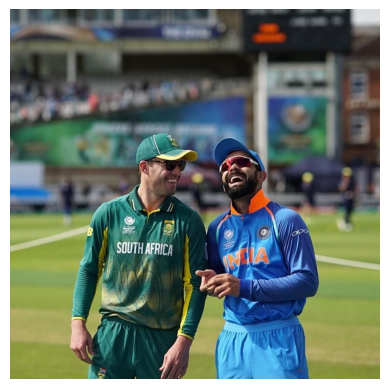

In [7]:
import matplotlib.pyplot as plt
from PIL import Image  #Imports the required image libraries

img = Image.open("wp7751170-abd-and-virat-wallpapers (1).jpg") #This opens the image

plt.imshow(img)
plt.axis("off")
plt.show()


## Image Cropping

### Student Practice
Crop the **center 200x200 region** of your image (not a random corner — think about how to calculate the center offset from `img_array.shape`), store it in a variable called `crop`, and display it.


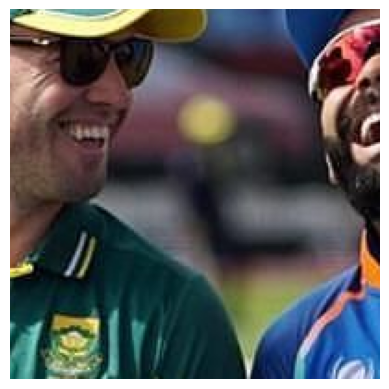

In [9]:
# Write your cropping code here
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open("wp7751170-abd-and-virat-wallpapers (1).jpg")
img_array = np.array(img)

h, w = img_array.shape[:2]

start_y = (h - 200) // 2  #Calculates the center for offsets
start_x = (w - 200) // 2   #AP24110012036


crop = img_array[start_y:start_y+200, start_x:start_x+200]  # It Crops the center 200x200

plt.imshow(crop)
plt.axis("off")    ## Display the resized image
plt.show()

### Quick demo: showing multiple images side by side

You'll want to display more than one image at once in the tasks below (e.g. two flipped versions, or three RGB channels). `plt.subplots()` lets you do this in a grid. Study this small example, then reuse the pattern.


## Image Flipping

### Student Practice
Produce and display both a vertical flip and a horizontal flip of your image using slicing (`[::-1]`), without using any built-in flip function.


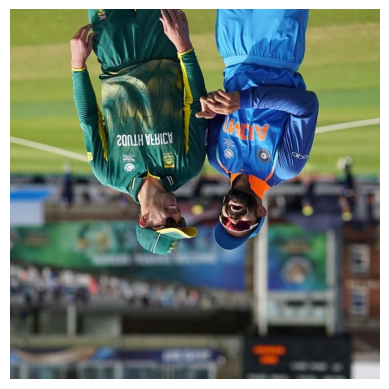

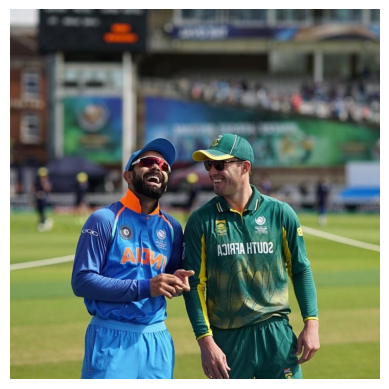

In [15]:
import numpy as np
import matplotlib.pyplot as plt

vertical_flip = img_array[::-1, :] # This line instructs the image to be Vertical flip (top ↔ bottom)

horizontal_flip = img_array[:, ::-1] # This line instructs the image to be Horizontal flip (left ↔ right)

plt.imshow(vertical_flip)
plt.axis("off")              #AP24110012036
plt.show()  # Displays the vertical flip

plt.imshow(horizontal_flip)
plt.axis("off")
plt.show()     # Displays the horizontal flip

## RGB Channel Analysis

RGB channels:

- 0 - Red
- 1 - Green
- 2 - Blue

### Student Practice
Extract the red, green, and blue channels separately, and display each one using `plt.imshow(channel, cmap="gray")` so you can see which areas of the image are strongest in each color.


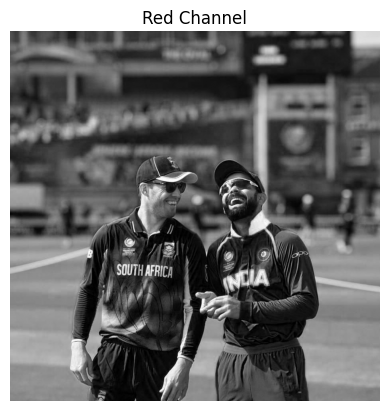

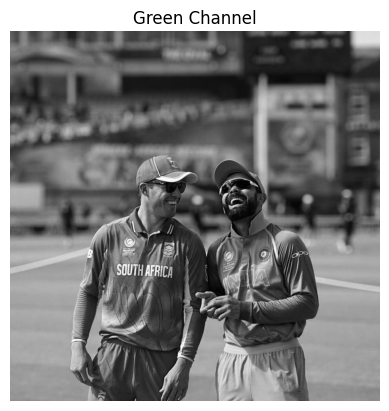

(np.float64(-0.5), np.float64(929.5), np.float64(929.5), np.float64(-0.5))

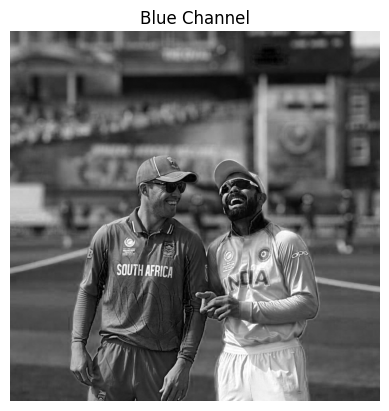

In [16]:
# Write your RGB channel code here
import matplotlib.pyplot as plt

red = img_array[:, :, 0]  #This  Extracts the RGB channels
green = img_array[:, :, 1]
blue = img_array[:, :, 2]
#AP24110012036
plt.imshow(red, cmap="gray")  #This Displays the Red channel
plt.title("Red Channel")
plt.axis("off")
plt.show()

plt.imshow(green, cmap="gray")  #This  Displays Green channel
plt.title("Green Channel")
plt.axis("off")
plt.show()
#AP24110012036
plt.imshow(blue, cmap="gray")   # This Displays the Blue channel
plt.title("Blue Channel")
plt.axis("off")

## Brightness Analysis

### Student Practice
Calculate the average brightness of your image using `np.mean()`. Then calculate the average brightness of just the red channel, just the green channel, and just the blue channel. Which channel is brightest? Write your answer below the code.


In [17]:
# Write your brightness code here
import numpy as np

overall_brightness = np.mean(img_array) # this gives Overall average brightness

red = img_array[:, :, 0]  # Separate RGB channels red color
green = img_array[:, :, 1]   #green color
blue = img_array[:, :, 2]   #blue color

red_brightness = np.mean(red)# Average brightness of each channel red in this line
green_brightness = np.mean(green)#green color
blue_brightness = np.mean(blue) #blue color

print("Overall brightness:", overall_brightness)  #Calculates the brightness overall
print("Red brightness:", red_brightness)  #red brightness
print("Green brightness:", green_brightness)  #green brightness
print("Blue brightness:", blue_brightness) # blue brightness

brightness = {                      #AP24110012036
    "Red": red_brightness,
    "Green": green_brightness,    # calculates Average brightness of each channel
    "Blue": blue_brightness     #AP24110012036
}

brightest = max(brightness, key=brightness.get)  #gives the highest brightness
print("Brightest channel:", brightest)


Overall brightness: 95.47018036767257
Red brightness: 88.76610590819747
Green brightness: 103.7909330558446
Blue brightness: 93.8535021389756
Brightest channel: Green


*Your answer:*


## Thresholding

Convert the image into pure black-and-white using `np.where()`.

### Student Practice
1. Convert the image to grayscale by averaging the 3 channels (`axis=2`).
2. Use `np.where(gray > 128, 255, 0)` to create a binary (black/white) version.
3. Display the result.
4. Try a different threshold (e.g. 100 or 180) and observe how it changes the result.


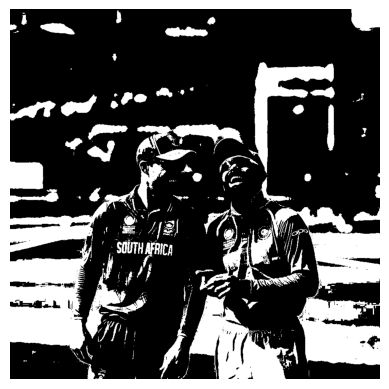

In [18]:
# Write your thresholding code here
import numpy as np
import matplotlib.pyplot as plt  #AP24110012036

#Convert RGB image to grayscale
gray = np.mean(img_array, axis=2)

#Create binary image using threshold 128
binary = np.where(gray > 128, 255, 0)

#Displays the binary image
plt.imshow(binary, cmap="gray")
plt.axis("off")
plt.show()

# Part 15: Text Analysis Using NumPy (NLP Track)

## Why this matters for ML/NLP

Before any NLP model (sentiment classifier, spam detector, chatbot) can process text, the text must be converted into numbers — this is called **vectorization**. NumPy arrays are the underlying data structure for almost every text representation: word counts, one-hot vectors, TF-IDF vectors, and even word embeddings are all just NumPy (or NumPy-like) arrays.

In this section, you'll build a small text analysis pipeline entirely with NumPy — no external NLP libraries — so you understand what's actually happening under the hood before you use libraries like `scikit-learn` or `nltk` later in the course.


# Mini Project: Image Analyzer

Write a single program (you can reuse code from above) that prints/displays all of the following for your uploaded image, in order:

1. Image height, width, and number of channels
2. Average brightness (overall, and per channel)
3. The cropped center region
4. Both flipped versions (vertical and horizontal)
5. All 3 RGB channels shown separately
6. The thresholded (black/white) version

### Self-check before you submit
- [ ] I wrote the code myself rather than only uncommenting given code
- [ ] I can explain what every line does, not just that it runs
- [ ] My image display uses `plt.axis("off")` and looks correct
- [ ] I answered all reflection questions in my own words

## Reflection Questions

1. Why is NumPy faster than Python lists? (Refer back to your Part 1 answer — refine it if needed.)

2. Explain broadcasting with an example of your own.

3. What does image shape `(512,512,3)` represent?

4. Why should we avoid printing complete image arrays?

5. Explain RGB channels.

6. Where might you use this exact image-array workflow in a real machine learning project (e.g. what comes right before feeding an image into a CNN)?


## Step 1: From Text to Tokens

The first step in any NLP pipeline is **tokenization** — splitting text into individual words.

### Demonstration


In [ ]:
sentence = "NumPy makes numerical computing fast and NumPy makes arrays powerful" # Convert the sentence to lowercase and split it into individual words


# Basic tokenization: lowercase + split on spaces
tokens = sentence.lower().split()
print(tokens) # Display the list of words



['numpy', 'makes', 'numerical', 'computing', 'fast', 'and', 'numpy', 'makes', 'arrays', 'powerful']


### Student Practice

Tokenize this sentence the same way: `"Data Science and Machine Learning use NumPy arrays every single day"`. Store the result in a variable called `tokens2`.


In [ ]:
# Write your answer here
# Tokenize the sentence by converting it to lowercase and splitting by spaces
tokens2 = "Data Science and Machine Learning use NumPy arrays every single day".lower().split()

# Display the tokens
print(tokens2)

['data', 'science', 'and', 'machine', 'learning', 'use', 'numpy', 'arrays', 'every', 'single', 'day']


## Step 2: Building a Vocabulary

A **vocabulary** is the set of all unique words across your text(s). We'll use `np.unique()` — the same function idea you used earlier for arrays of numbers, now applied to an array of words.


In [ ]:
# Convert the list of tokens into a NumPy array
tokens_array = np.array(tokens)

# Find all unique words and arrange them alphabetically
vocabulary = np.unique(tokens_array)

# Display the unique words
print("Vocabulary:", vocabulary)

# Display the total number of unique words
print("Vocabulary size:", len(vocabulary))

Vocabulary: ['and' 'arrays' 'computing' 'fast' 'makes' 'numerical' 'numpy' 'powerful']
Vocabulary size: 8


### Student Practice

Build the vocabulary for `tokens2` from Step 1. How many unique words does it contain?


In [ ]:
# Write your answer here
# Convert tokens2 into a NumPy array
tokens2_array = np.array(tokens2)

# Find the unique words in tokens2
vocabulary2 = np.unique(tokens2_array)

# Display the vocabulary and its size
print("Vocabulary:", vocabulary2)
print("Vocabulary size:", len(vocabulary2))

Vocabulary: ['and' 'arrays' 'data' 'day' 'every' 'learning' 'machine' 'numpy'
 'science' 'single' 'use']
Vocabulary size: 11


## Step 3: Word Frequency Vector (Bag-of-Words)

A **bag-of-words** vector represents a sentence as an array of word counts, one count per vocabulary word — this ignores word order but captures *what* words appear and *how often*.

### Demonstration: build a word-count vector by hand using NumPy


In [ ]:
def bag_of_words_vector(tokens, vocabulary):
    # For each word in the vocabulary, count how many times it appears
    # in the list of tokens
    vector = np.array([np.sum(np.array(tokens) == word) for word in vocabulary])

    # Return the word-count vector
    return vector

# Create the Bag-of-Words vector for the sentence
vec = bag_of_words_vector(tokens, vocabulary)

# Display the vocabulary
print(vocabulary)

# Display the number of times each word appears
print(vec)


['and' 'arrays' 'computing' 'fast' 'makes' 'numerical' 'numpy' 'powerful']
[1 1 1 1 2 1 2 1]


### Student Practice — predict then check

Before running, predict: which word(s) will have a count of 2 in the vector above? (Hint: look back at the original sentence — which word repeats?)

*Your prediction:*

Now build the bag-of-words vector for `tokens2` using its own vocabulary, and check your prediction concept applies the same way.


In [ ]:
# Write your answer here
# Build the Bag-of-Words vector for tokens2
vec2 = bag_of_words_vector(tokens2, vocabulary2)

# Display the vocabulary
print(vocabulary2)

# Display the Bag-of-Words vector
print(vec2)

['and' 'arrays' 'data' 'day' 'every' 'learning' 'machine' 'numpy'
 'science' 'single' 'use']
[1 1 1 1 1 1 1 1 1 1 1]


## Step 4: Comparing Two Sentences (Cosine Similarity)

Once text is turned into number vectors, we can measure how *similar* two sentences are using **cosine similarity** — a formula you'll see constantly in NLP and recommendation systems:

$$\text{cosine similarity} = \frac{A \cdot B}{\|A\| \times \|B\|}$$

This measures the angle between two vectors, not their length — so it works even if one sentence is longer than another.

### Demonstration


In [ ]:
# Define the first sentence
sentence_a = "machine learning uses numpy arrays"

# Define the second sentence
sentence_b = "deep learning also uses numpy arrays heavily"

# Convert both sentences to lowercase and split them into words
tokens_a = sentence_a.lower().split()
tokens_b = sentence_b.lower().split()

# Create one shared vocabulary containing unique words from both sentences
combined_vocab = np.unique(np.array(tokens_a + tokens_b))

# Convert each sentence into a Bag-of-Words vector
vec_a = bag_of_words_vector(tokens_a, combined_vocab)
vec_b = bag_of_words_vector(tokens_b, combined_vocab)

# Display the vectors
print("Vector A:", vec_a)
print("Vector B:", vec_b)

# Calculate cosine similarity between the two vectors
cosine_sim = np.dot(vec_a, vec_b) / (
    np.linalg.norm(vec_a) * np.linalg.norm(vec_b)
)

# Display the similarity score
print("Cosine similarity:", cosine_sim)

Vector A: [0 1 0 0 1 1 1 1]
Vector B: [1 1 1 1 1 0 1 1]
Cosine similarity: 0.6761234037828131


### Student Practice

Pick two sentences of your own (write them below) — one pair that should be *similar* in meaning/topic, and one pair that should be *very different*. Compute the cosine similarity for both pairs and confirm your intuition matches the numbers.


In [ ]:
sentence1 = "machine learning is useful for data analysis"
sentence2 = "machine learning helps with data analysis"

tokens1 = sentence1.lower().split()
tokens2 = sentence2.lower().split()

# Build a shared vocabulary
vocab = np.unique(np.array(tokens1 + tokens2))

# Create Bag-of-Words vectors
vec1 = bag_of_words_vector(tokens1, vocab)
vec2 = bag_of_words_vector(tokens2, vocab)

# Calculate cosine similarity
similarity1 = np.dot(vec1, vec2) / (
    np.linalg.norm(vec1) * np.linalg.norm(vec2)
)

print("Similar sentences similarity:", similarity1)

Similar sentences similarity: 0.6172133998483676


**Reflection:** In your own words, why does cosine similarity give a value close to 1 for similar sentences and close to 0 for unrelated sentences? What would a `cosine similarity` of exactly 1 mean about two vectors?

*Your answer:* **Your answer:**

Cosine similarity is close to 1 when two sentences are similar because they have many words in common. It is close to 0 when the sentences are very different and have few or no words in common. A cosine similarity of exactly **1** means the two vectors are completely similar in the way their values are arranged.



## Step 5: Most Frequent Words

### Student Practice

Take any paragraph of your choice (3-4 sentences, write it below as a string). Then:
1. Tokenize it.
2. Build its vocabulary and word-count vector (reuse `bag_of_words_vector`).
3. Use NumPy to find and print the **top 3 most frequent words** (hint: look at sorting — `np.argsort()` sorts indices by value, and slicing with `[::-1]` reverses order).


In [ ]:
# Write your answer here
# Write a paragraph with 3-4 sentences
paragraph = """Machine learning is useful for solving problems.
Machine learning helps computers learn from data.
Data is important for machine learning projects.
Machine learning can be used in many applications."""

# Tokenize the paragraph
tokens = paragraph.lower().split()

# Build the vocabulary
vocab = np.unique(np.array(tokens))

# Build the word-count vector
counts = bag_of_words_vector(tokens, vocab)

# Get the indices of the 3 most frequent words
top_indices = np.argsort(counts)[::-1][:3]

# Print the top 3 words and their counts
print("Top 3 most frequent words:")

for i in top_indices:
    print(vocab[i], ":", counts[i])

Top 3 most frequent words:
machine : 4
learning : 4
is : 2


# Mini Project: Simple Text Similarity Checker (NLP Track)

Build a small program that:

1. Takes **three** short sentences of your choice (write them as strings).
2. Tokenizes all three and builds one shared vocabulary across all of them.
3. Converts each sentence into a bag-of-words vector using that shared vocabulary.
4. Computes cosine similarity between every pair of sentences (3 pairs total: 1-2, 1-3, 2-3).
5. Prints which two sentences are the **most similar** to each other, based on the highest cosine similarity score.

### Self-check before you submit
- [.] I wrote my own three sentences (not copied from the notebook)
- [.] I can explain what a bag-of-words vector represents, in my own words
- [.] I can explain why cosine similarity works even when sentences are different lengths
- [.] My program correctly identifies and prints the most similar pair

## Reflection Questions (NLP Track)

1. Why do we need to convert text into numbers before a machine learning model can use it?

2. What information does a bag-of-words vector *lose* about the original sentence? (Hint: think about what `split()` and counting alone doesn't capture.)

3. Why might cosine similarity be a better similarity measure than simply comparing raw word-count differences?

4. Name one real-world application that likely uses something like this text-vectorization + similarity approach (e.g. search engines, plagiarism checkers, recommendation systems — pick one and explain briefly).


In [ ]:
# Mini Project: Simple Text Similarity Checker (NLP Track)
import numpy as np

# 1. Three original sentences
sentence1 = "Students practice coding in the computer lab"
sentence2 = "Students practice programming in the computer lab"
sentence3 = "The weather is pleasant today"

# 2. Tokenize all three sentences
tokens1 = sentence1.lower().split()
tokens2 = sentence2.lower().split()
tokens3 = sentence3.lower().split()

# Build one shared vocabulary
vocabulary = np.unique(np.array(tokens1 + tokens2 + tokens3))

print("Shared Vocabulary:")
print(vocabulary)

# 3. Convert each sentence into a bag-of-words vector
vec1 = np.array([np.sum(np.array(tokens1) == word) for word in vocabulary])
vec2 = np.array([np.sum(np.array(tokens2) == word) for word in vocabulary])
vec3 = np.array([np.sum(np.array(tokens3) == word) for word in vocabulary])

print("\nBag-of-Words Vectors:")
print("Sentence 1:", vec1)
print("Sentence 2:", vec2)
print("Sentence 3:", vec3)

# 4. Function to calculate cosine similarity
def cosine_similarity(v1, v2):
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

# Calculate similarity for all three pairs
similarity_12 = cosine_similarity(vec1, vec2)
similarity_13 = cosine_similarity(vec1, vec3)
similarity_23 = cosine_similarity(vec2, vec3)

print("\nCosine Similarities:")
print("Sentence 1 and Sentence 2:", similarity_12)
print("Sentence 1 and Sentence 3:", similarity_13)
print("Sentence 2 and Sentence 3:", similarity_23)

# 5. Find the most similar pair
similarities = {
    "Sentence 1 and Sentence 2": similarity_12,
    "Sentence 1 and Sentence 3": similarity_13,
    "Sentence 2 and Sentence 3": similarity_23
}

most_similar = max(similarities, key=similarities.get)

print("\nMost similar pair:", most_similar)
print("Highest cosine similarity:", similarities[most_similar])

Shared Vocabulary:
['coding' 'computer' 'in' 'is' 'lab' 'pleasant' 'practice' 'programming'
 'students' 'the' 'today' 'weather']

Bag-of-Words Vectors:
Sentence 1: [1 1 1 0 1 0 1 0 1 1 0 0]
Sentence 2: [0 1 1 0 1 0 1 1 1 1 0 0]
Sentence 3: [0 0 0 1 0 1 0 0 0 1 1 1]

Cosine Similarities:
Sentence 1 and Sentence 2: 0.857142857142857
Sentence 1 and Sentence 3: 0.16903085094570328
Sentence 2 and Sentence 3: 0.16903085094570328

Most similar pair: Sentence 1 and Sentence 2
Highest cosine similarity: 0.857142857142857
